# 05 - Comparación de modelos

**Objetivo:** comparar las dos configuraciones de cada modelo (sin Dropout y con Dropout),
elegir la mejor y evaluar los dos modelos finales con el conjunto de test.

In [1]:
#Cargamos los historiales
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras.models import load_model
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve, confusion_matrix)

# Historiales de entrenamiento guardados en los notebooks 03 y 04
historiales = {
    "Modelo 1 - A (sin Dropout)": pd.read_csv("../models/historial_modelo1_sin_dropout.csv"),
    "Modelo 1 - B (Dropout 0.5)": pd.read_csv("../models/historial_modelo1_con_dropout.csv"),
    "Modelo 2 - A (sin Dropout)": pd.read_csv("../models/historial_modelo2_sin_dropout.csv"),
    "Modelo 2 - B (Dropout 0.3)": pd.read_csv("../models/historial_modelo2_con_dropout.csv"),
}

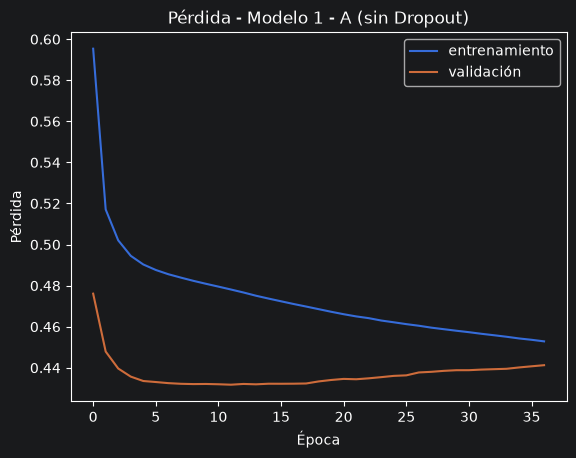

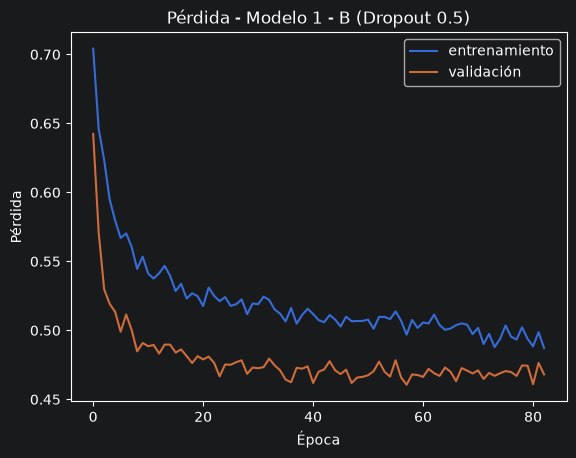

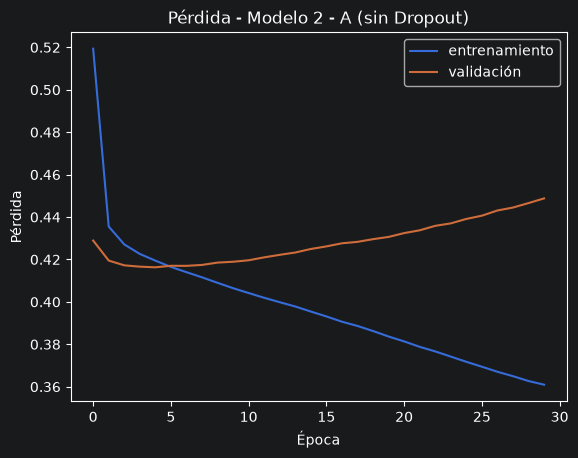

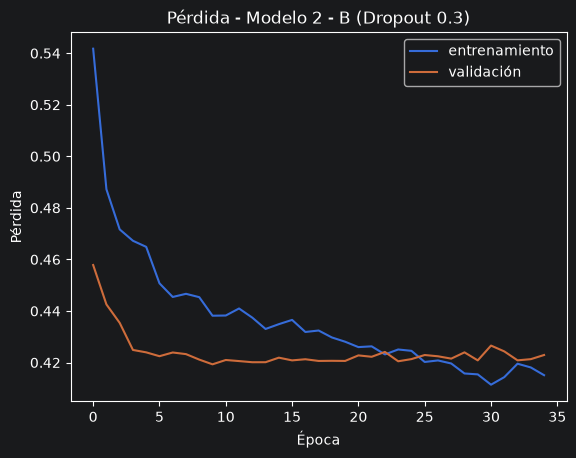

In [2]:
#Curvas de pérdida de cada configuración
# Una gráfica por configuración: pérdida de entrenamiento y de validación
for nombre, h in historiales.items():
    plt.plot(h["loss"], label="entrenamiento")
    plt.plot(h["val_loss"], label="validación")
    plt.title("Pérdida - " + nombre)
    plt.xlabel("Época")
    plt.ylabel("Pérdida")
    plt.legend()
    plt.show()

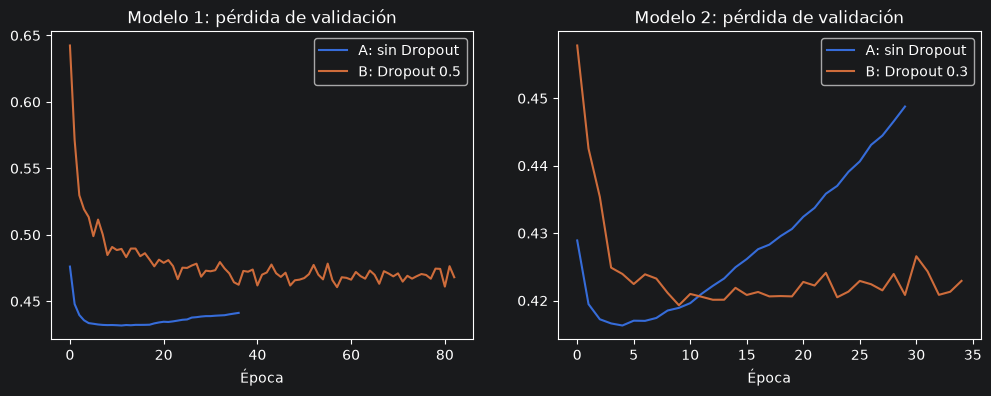

In [3]:
#Comparar las configuraciones en una sola gráfica
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(historiales["Modelo 1 - A (sin Dropout)"]["val_loss"], label="A: sin Dropout")
ax[0].plot(historiales["Modelo 1 - B (Dropout 0.5)"]["val_loss"], label="B: Dropout 0.5")
ax[0].set_title("Modelo 1: pérdida de validación")

ax[1].plot(historiales["Modelo 2 - A (sin Dropout)"]["val_loss"], label="A: sin Dropout")
ax[1].plot(historiales["Modelo 2 - B (Dropout 0.3)"]["val_loss"], label="B: Dropout 0.3")
ax[1].set_title("Modelo 2: pérdida de validación")

for eje in ax:
    eje.set_xlabel("Época")
    eje.legend()
plt.show()

In [4]:
#Tabla resumen de las configuraciones
filas = []
for nombre, h in historiales.items():
    mejor = h["val_loss"].idxmin()   # época con menor pérdida de validación
    filas.append({
        "Configuración": nombre,
        "Épocas entrenadas": len(h),
        "Mejor época": mejor + 1,
        "Mejor val_loss": h["val_loss"].min(),
        "Subida de val_loss después del mínimo": h["val_loss"].iloc[-1] - h["val_loss"].min(),
    })

tabla = pd.DataFrame(filas).round(4)
tabla

,Configuración,Épocas entrenadas,Mejor época,Mejor val_loss,Subida de val_loss después del mínimo
0,Modelo 1 - A (sin Dropout),37,12,0.4318,0.0095
1,Modelo 1 - B (Dropout 0.5),83,58,0.4606,0.0075
2,Modelo 2 - A (sin Dropout),30,5,0.4163,0.0325
3,Modelo 2 - B (Dropout 0.3),35,10,0.4193,0.0036


In [5]:
#Evaluar los dos modelos elegidos con test
# Recién ahora se usa el conjunto de test
test = pd.read_csv("../data/processed/test.csv")
X_test = test.drop(columns="Churn").values.astype("float32")
y_test = test["Churn"].values

modelo1 = load_model("../models/model1.keras")
modelo2 = load_model("../models/model2.keras")

prob1 = modelo1.predict(X_test, verbose=0).ravel()
prob2 = modelo2.predict(X_test, verbose=0).ravel()

modelos = [("Modelo 1", prob1), ("Modelo 2", prob2)]

In [6]:
filas = []
for nombre, prob in modelos:
    pred = (prob > 0.5).astype(int)
    filas.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision (se va)": precision_score(y_test, pred),
        "Recall (se va)": recall_score(y_test, pred),
        "F1 (se va)": f1_score(y_test, pred),
        "AUC": roc_auc_score(y_test, prob),
    })

pd.DataFrame(filas).round(3)

,Modelo,Accuracy,Precision (se va),Recall (se va),F1 (se va),AUC
0,Modelo 1,0.754,0.509,0.741,0.603,0.839
1,Modelo 2,0.796,0.593,0.608,0.601,0.840


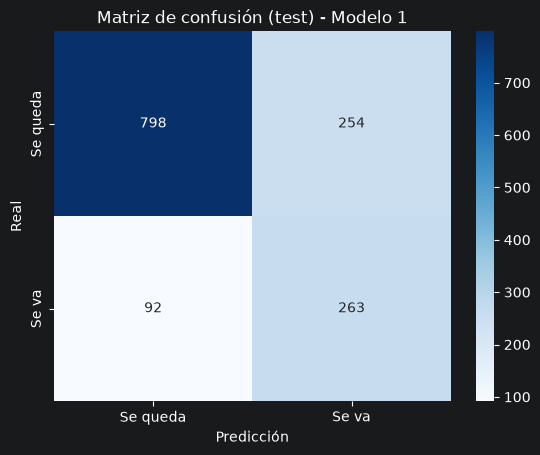

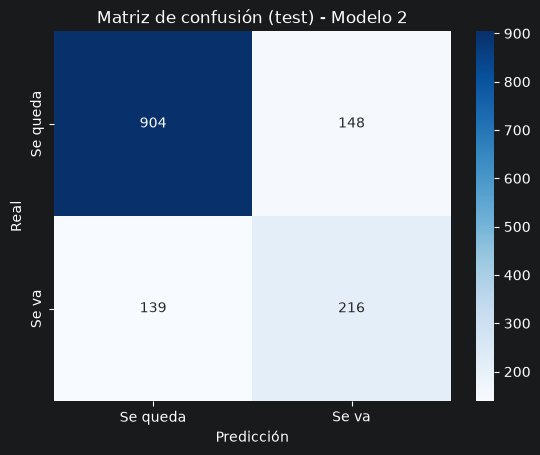

In [7]:
#Matrices de confusión
for nombre, prob in modelos:
    pred = (prob > 0.5).astype(int)
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues",
                xticklabels=["Se queda", "Se va"], yticklabels=["Se queda", "Se va"])
    plt.xlabel("Predicción")
    plt.ylabel("Real")
    plt.title("Matriz de confusión (test) - " + nombre)
    plt.show()

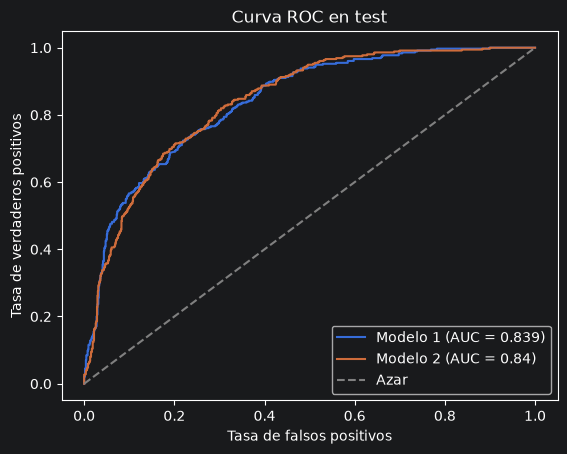

In [8]:
#Curva ROC de los dos modelos
for nombre, prob in modelos:
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, label=nombre + " (AUC = " + str(round(roc_auc_score(y_test, prob), 3)) + ")")

plt.plot([0, 1], [0, 1], "--", color="gray", label="Azar")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.title("Curva ROC en test")
plt.legend()
plt.show()

In [9]:
#¿Qué tan reales son las probabilidades?
print("Churn real en test:", round(y_test.mean(), 3))
print("Probabilidad media del Modelo 1:", round(prob1.mean(), 3))
print("Probabilidad media del Modelo 2:", round(prob2.mean(), 3))

Churn real en test: 0.252
Probabilidad media del Modelo 1: 0.388
Probabilidad media del Modelo 2: 0.285


## Conclusiones

### Modelo 1 (clasificación binaria)
Se compararon dos configuraciones, ambas entrenadas con `class_weight`. Las métricas son
sobre el conjunto de validación (1,125 clientes, de los cuales 295 se fueron):

| Configuración | Mejor época | Mejor val_loss | Recall (se va) | Precisión (se va) | F1 (se va) | Accuracy |
|---|---|---|---|---|---|---|
| A: sin Dropout | 12 | 0.4318 | 0.65 | 0.56 | 0.60 | 0.78 |
| B: Dropout 0.5 | 58 | 0.4606 | 0.75 | 0.53 | 0.62 | 0.76 |

La configuración A obtuvo la menor pérdida de validación, pero se eligió la **B** porque
detecta más clientes que se van: su recall fue de 0.75 contra 0.65, y su F1 fue algo mayor
(0.62 contra 0.60). A cambio tiene menos precisión (0.53 contra 0.56) y menos accuracy
(0.76 contra 0.78). Para una empresa de telecomunicaciones es más costoso perder a un
cliente que contactar a uno de más, por eso se priorizó el recall. Además, B mostró una
subida de val_loss menor después de su mínimo (0.0075 contra 0.0095). Más tarde, en el
conjunto de test (que no se usó para elegir), el recall de B fue 0.741, parecido al de
validación, lo que indica que el resultado se mantiene con datos nuevos.

### Modelo 2 (scoring de riesgo)

| Configuración | Mejor época | Mejor val_loss | Subida de val_loss después del mínimo |
|---|---|---|---|
| A: sin Dropout | 5 | 0.4163 | 0.0325 |
| B: Dropout 0.3 | 10 | 0.4193 | 0.0036 |

La diferencia entre A y B es muy pequeña (unas tres milésimas). Se eligió la **A** por tener
la menor pérdida de validación, y se confirmó repitiendo el entrenamiento con 5 semillas
distintas en el notebook 04. Como el entrenamiento usa `restore_best_weights`, el modelo
guardado conserva los pesos de la mejor época y la subida posterior no lo afecta.

### Comparación en test

| Modelo | Accuracy | Precisión (se va) | Recall (se va) | F1 (se va) | AUC |
|---|---|---|---|---|---|
| Modelo 1 | 0.754 | 0.509 | 0.741 | 0.603 | 0.839 |
| Modelo 2 | 0.796 | 0.593 | 0.608 | 0.601 | 0.840 |

- Los dos modelos tienen un AUC casi igual (0.839 y 0.840), así que distinguen igual de bien
  a los clientes que se van de los que se quedan.
- El Modelo 1 detecta el 74.1% de los clientes que se van, pero solo la mitad de los que
  marca como "se va" realmente se va (precisión de 50.9%). Esto es consecuencia de `class_weight`.
- El Modelo 2 detecta menos clientes que se van (60.8%), pero acierta más cuando lo indica
  (precisión de 59.3%) y tiene mayor accuracy.
- Probabilidad media predicha, comparada con el churn real en test (25.2%): el Modelo 1
  da 38.8% y el Modelo 2 da 28.5%. El Modelo 1 sobrestima las probabilidades porque se
  entrenó con `class_weight`. El Modelo 2, entrenado sin ese ajuste, da probabilidades
  más cercanas a la realidad, y por eso sus valores sirven para definir los niveles de
  riesgo (Bajo, Medio, Alto y Crítico).

### Modelo recomendado
No hay un modelo mejor en todo, cada uno tiene su uso:
- **Modelo 1:** conviene para campañas de retención donde es más grave perder a un cliente
  que contactar a uno de más, porque detecta más clientes en fuga.
- **Modelo 2:** conviene para priorizar clientes por nivel de riesgo, porque da una
  probabilidad más realista y comete menos falsas alarmas.
- En la API, el Modelo 1 responde `/predict/churn` y el Modelo 2 responde `/predict/risk_score`.